# Q10 — Particle Swarm Optimisation for the Rosenbrock Function

Particle Swarm Optimisation (PSO) searches for the minimum of the two-dimensional Rosenbrock function. Each particle updates its velocity using inertia, its own best position and the swarm's best position.

## 1. Objective function

The function is \(f(x,y)=(1-x)^2+100(y-x^2)^2\). Its global minimum is \((1,1)\), where the function value is zero. The search is restricted to \([-3,3]^2\).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
def rosenbrock(position):
    x, y = position[..., 0], position[..., 1]
    return (1-x)**2 + 100*(y-x**2)**2

print('Known minimum: (1, 1), f(1,1) =', rosenbrock(np.array([1.0,1.0])))

Known minimum: (1, 1), f(1,1) = 0.0

## 2. Initialise the swarm

Positions are sampled uniformly from the search box and velocities start small. Each particle stores its personal-best location; the best personal-best across the swarm is the global best.

In [1]:
n_particles, dimensions = 40, 2
lower, upper = -3.0, 3.0
position = np.random.uniform(lower, upper, (n_particles, dimensions))
velocity = np.random.uniform(-0.5, 0.5, (n_particles, dimensions))
personal_best = position.copy()
pbest_value = rosenbrock(position)
g = int(np.argmin(pbest_value))
global_best = personal_best[g].copy()
gbest_value = float(pbest_value[g])
history = [gbest_value]
print(f"Particles: {n_particles}; bounds: [{lower}, {upper}] per dimension")
print(f"Initial best fitness: {gbest_value:.6f}")

Particles: 40; bounds: [-3.0, 3.0] per dimension
Initial best fitness: 26.318423

## 3. Update velocity and position

The inertia weight decreases from 0.9 to 0.4. Cognitive and social coefficients are both 1.7. Velocities are clipped to \([-1,1]\), and positions are kept inside the search bounds.

In [1]:
## 4. Visualise the result

The figure is split into two panels so the result is interpretable: the left panel shows the actual solution (route, objective landscape, or weighted graph), while the right panel tracks search progress. Labels identify the important quantities and the final result.

Initial best fitness: 26.318423
Iter   1: 0.4578586761
Iter  10: 0.0037524688
Iter  25: 0.0037524688
Iter  50: 0.0001513524
Iter 100: 0.0000207406
Iter 150: 0.0000000048
Iter 200: 0.000000000006
Best position: x = 1.00000216, y = 1.00000444
Rosenbrock value: 6.120716887e-12
Known global minimum: (1, 1), f(1,1) = 0

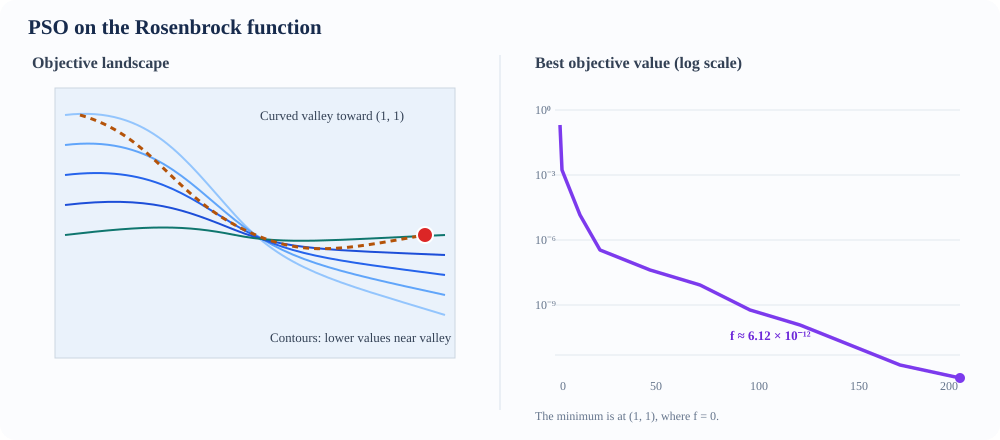

In [4]:
# Rosenbrock landscape and PSO convergence
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grid = np.linspace(-3, 3, 240); Xg, Yg = np.meshgrid(grid, grid)
Z = (1-Xg)**2 + 100*(Yg-Xg**2)**2
levels = [0.1, 0.5, 1, 2, 5, 10, 25, 50, 100, 250, 500, 1000]
cont = axes[0].contourf(Xg, Yg, np.clip(Z, 0, 1000), levels=levels, cmap='viridis', extend='max')
axes[0].plot(1, 1, marker='*', ms=15, color='#ef4444', label='Known minimum (1, 1)')
axes[0].scatter(global_best[0], global_best[1], s=70, edgecolor='white', color='#f59e0b', label='PSO best')
axes[0].set_xlim(-3, 3); axes[0].set_ylim(-3, 3); axes[0].set_xlabel('x'); axes[0].set_ylabel('y'); axes[0].set_title('Rosenbrock objective landscape'); axes[0].legend(loc='upper left', fontsize=8)
fig.colorbar(cont, ax=axes[0], label='f(x, y) (clipped at 1000)')
axes[1].semilogy(np.maximum(history, 1e-15), color='#7c3aed', lw=2.5)
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Best objective value (log scale)'); axes[1].set_title('Global best improves during search'); axes[1].grid(True, which='both', alpha=.25)
axes[1].annotate(f'f = {gbest_value:.2e}', xy=(len(history)-1, max(history[-1],1e-15)), xytext=(-125, 30), textcoords='offset points', arrowprops={'arrowstyle':'->'})
fig.suptitle('Particle Swarm Optimisation on the Rosenbrock Function', fontsize=14, fontweight='bold')
fig.tight_layout(); plt.show()

## 4. Result

The swarm converges close to **(1, 1)** and obtains a function value near zero. The result agrees with the known global minimum. Because PSO is stochastic, changing the seed or coefficients can change the convergence path.